[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-cheminformatics-course/blob/main/notebooks/06_standardization_curation.ipynb)

# 06 · Structure Standardization and Data Curation

*Practical Cheminformatics Course · Hamza Hentabli, Ph.D. · ~55 min*

*Garbage in, garbage out.* Public bioactivity data mixes salts and free bases, charged
and neutral forms, tautomers, unit conventions, and repeated measurements. Models trained on
uncurated data quietly learn the noise. This notebook builds a small, transparent curation pipeline.

**Learning objectives.** By the end of this notebook you will be able to:

- explain why the same compound appears under different structures in public data
- standardize structures with RDKit's `rdMolStandardize` (cleanup, salts, charges, tautomers)
- convert IC50 values to pIC50 and filter activity records
- aggregate replicate measurements into one value per compound and flag inconsistent ones

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Install requirements.txt once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'rdkit'], check=True)
    if not os.path.isdir("practical-cheminformatics-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-cheminformatics-course.git"], check=True)
    DATA_DIR = "practical-cheminformatics-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
RDLogger.DisableLog("rdApp.*")
from rdkit.Chem.MolStandardize import rdMolStandardize

## 1. The problems, one molecule at a time

The structures below are textbook examples written by hand to illustrate each problem.

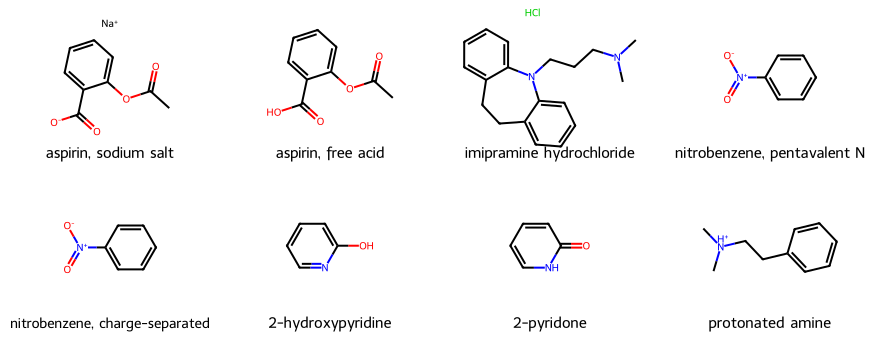

In [3]:
examples = {
    "aspirin, sodium salt": "CC(=O)Oc1ccccc1C(=O)[O-].[Na+]",
    "aspirin, free acid": "CC(=O)Oc1ccccc1C(=O)O",
    "imipramine hydrochloride": "CN(C)CCCN1c2ccccc2CCc2ccccc21.Cl",
    "nitrobenzene, pentavalent N": "c1ccccc1N(=O)=O",
    "nitrobenzene, charge-separated": "c1ccccc1[N+](=O)[O-]",
    "2-hydroxypyridine": "Oc1ccccn1",
    "2-pyridone": "O=c1cccc[nH]1",
    "protonated amine": "C[NH+](C)CCc1ccccc1",
}
mols = [Chem.MolFromSmiles(s) for s in examples.values()]
Draw.MolsToGridImage(mols, molsPerRow=4, subImgSize=(220, 170), legends=list(examples))

In [4]:
pd.DataFrame({"input SMILES": list(examples.values()),
              "InChIKey": [Chem.MolToInchiKey(m) for m in mols]}, index=list(examples))

,input SMILES,InChIKey
"aspirin, sodium salt",CC(=O)Oc1ccccc1C(=O)[O-].[Na+],JZLOKWGVGHYBKD-UHFFFAOYSA-M
"aspirin, free acid",CC(=O)Oc1ccccc1C(=O)O,BSYNRYMUTXBXSQ-UHFFFAOYSA-N
imipramine hydrochloride,CN(C)CCCN1c2ccccc2CCc2ccccc21.Cl,XZZXIYZZBJDEEP-UHFFFAOYSA-N
"nitrobenzene, pentavalent N",c1ccccc1N(=O)=O,LQNUZADURLCDLV-UHFFFAOYSA-N
"nitrobenzene, charge-separated",c1ccccc1[N+](=O)[O-],LQNUZADURLCDLV-UHFFFAOYSA-N
2-hydroxypyridine,Oc1ccccn1,UBQKCCHYAOITMY-UHFFFAOYSA-N
2-pyridone,O=c1cccc[nH]1,UBQKCCHYAOITMY-UHFFFAOYSA-N
protonated amine,C[NH+](C)CCc1ccccc1,TXOFSCODFRHERQ-UHFFFAOYSA-O


Pairs that a chemist would call "the same compound" get **different** identifiers, so a naive
duplicate check misses them and a model sees them as different molecules.

## 2. A standardization function

| Step | RDKit tool | What it does |
|---|---|---|
| Cleanup | `rdMolStandardize.Cleanup` | sanitizes, normalizes functional groups (e.g. nitro), reionizes |
| Parent fragment | `LargestFragmentChooser` | removes counter-ions and solvents |
| Neutralize | `Uncharger` | neutralizes charges where possible |
| Canonical tautomer | `TautomerEnumerator.Canonicalize` | picks one tautomer consistently |

In [5]:
_lfc = rdMolStandardize.LargestFragmentChooser()
_uncharger = rdMolStandardize.Uncharger()
_tautomers = rdMolStandardize.TautomerEnumerator()

def standardize(smiles):
    """Return a standardized RDKit Mol, or None if the SMILES cannot be parsed."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    mol = rdMolStandardize.Cleanup(mol)
    mol = _lfc.choose(mol)
    mol = _uncharger.uncharge(mol)
    mol = _tautomers.Canonicalize(mol)
    return mol

std = [standardize(s) for s in examples.values()]
pd.DataFrame({"standardized SMILES": [Chem.MolToSmiles(m) for m in std],
              "InChIKey": [Chem.MolToInchiKey(m) for m in std]}, index=list(examples))

,standardized SMILES,InChIKey
"aspirin, sodium salt",CC(=O)Oc1ccccc1C(=O)O,BSYNRYMUTXBXSQ-UHFFFAOYSA-N
"aspirin, free acid",CC(=O)Oc1ccccc1C(=O)O,BSYNRYMUTXBXSQ-UHFFFAOYSA-N
imipramine hydrochloride,CN(C)CCCN1c2ccccc2CCc2ccccc21,BCGWQEUPMDMJNV-UHFFFAOYSA-N
"nitrobenzene, pentavalent N",O=[N+]([O-])c1ccccc1,LQNUZADURLCDLV-UHFFFAOYSA-N
"nitrobenzene, charge-separated",O=[N+]([O-])c1ccccc1,LQNUZADURLCDLV-UHFFFAOYSA-N
2-hydroxypyridine,O=c1cccc[nH]1,UBQKCCHYAOITMY-UHFFFAOYSA-N
2-pyridone,O=c1cccc[nH]1,UBQKCCHYAOITMY-UHFFFAOYSA-N
protonated amine,CN(C)CCc1ccccc1,TXOFSCODFRHERQ-UHFFFAOYSA-N


Each pair now collapses to the same standardized SMILES and InChIKey. In a real project,
document these choices: for example, whether you keep stereochemistry and which tautomer rules you use.

## 3. Curating real ChEMBL data

We use 1,000 binding IC50 records for **human acetylcholinesterase** (CHEMBL220) retrieved from the
ChEMBL 37 REST API (`data/chembl_cache/`). You will learn how to download such data yourself in Notebook 07.

In [6]:
raw = pd.read_csv(f"{DATA_DIR}/chembl_cache/activities_CHEMBL220_IC50.csv")
print(raw.shape)
raw[["molecule_chembl_id", "standard_relation", "standard_value", "standard_units",
     "pchembl_value", "data_validity_comment"]].head()

(1000, 14)


,molecule_chembl_id,standard_relation,standard_value,standard_units,pchembl_value,data_validity_comment
0,CHEMBL133897,=,750.0,nM,6.12,NaN
1,CHEMBL336398,=,100.0,nM,7.00,NaN
2,CHEMBL131588,>,50000.0,nM,NaN,NaN
3,CHEMBL130628,=,300.0,nM,6.52,NaN
4,CHEMBL130478,=,800.0,nM,6.10,NaN


In [7]:
print(raw["standard_units"].value_counts(dropna=False).to_string(), "\n")
print(raw["standard_relation"].value_counts(dropna=False).to_string(), "\n")
print(raw["data_validity_comment"].value_counts(dropna=False).to_string())

standard_units
nM    1000 

standard_relation
=      888
>       86
NaN     21
<        3
~        2 

data_validity_comment
NaN                      906
Outside typical range     94


### 3a. Record-level filters

We keep exact measurements (`=`), in nM, with a positive value, a structure, and no ChEMBL
data-validity warning. Every step is counted, so you can report a curation funnel in a methods section.

In [8]:
funnel = [("raw records", len(raw))]
df = raw.copy()
df = df[df["canonical_smiles"].notna()];             funnel.append(("has a structure", len(df)))
df = df[df["standard_relation"] == "="];             funnel.append(("exact value (relation '=')", len(df)))
df = df[df["standard_units"] == "nM"];               funnel.append(("units nM", len(df)))
df = df[df["standard_value"] > 0];                   funnel.append(("positive value", len(df)))
df = df[df["data_validity_comment"].isna()];         funnel.append(("no data-validity warning", len(df)))
pd.DataFrame(funnel, columns=["step", "records"])

,step,records
0,raw records,1000
1,has a structure,1000
2,exact value (relation '='),888
3,units nM,888
4,positive value,888
5,no data-validity warning,823


### 3b. IC50 → pIC50

pIC50 = −log10(IC50 in mol/L) = 9 − log10(IC50 in nM). Log-scale values are what QSAR models should predict.
ChEMBL's own `pchembl_value` lets us check the conversion.

In [9]:
df["pIC50"] = 9 - np.log10(df["standard_value"])
both = df.dropna(subset=["pchembl_value"])
print("max |our pIC50 - pchembl_value|:", (both["pIC50"] - both["pchembl_value"]).abs().max().round(3))

max |our pIC50 - pchembl_value|: 0.005


### 3c. Standardize structures and aggregate replicates

In [10]:
df["std_mol"] = df["canonical_smiles"].apply(standardize)
print("failed to standardize:", df["std_mol"].isna().sum())
df = df[df["std_mol"].notna()].copy()
df["std_smiles"] = df["std_mol"].apply(Chem.MolToSmiles)
df["inchikey"] = df["std_mol"].apply(Chem.MolToInchiKey)
print("unique ChEMBL molecule IDs:", df["molecule_chembl_id"].nunique())
print("unique standardized structures (InChIKey):", df["inchikey"].nunique())

failed to standardize: 0
unique ChEMBL molecule IDs: 600
unique standardized structures (InChIKey): 589


In [11]:
curated = (df.groupby("inchikey")
             .agg(smiles=("std_smiles", "first"),
                  chembl_ids=("molecule_chembl_id", lambda x: ";".join(sorted(set(x)))),
                  pIC50=("pIC50", "median"),
                  n_measurements=("pIC50", "size"),
                  pIC50_range=("pIC50", lambda x: x.max() - x.min()))
             .reset_index())
curated["inconsistent"] = curated["pIC50_range"] > 1.0     # replicates disagree by > 10-fold
print(len(curated), "unique compounds |", curated["inconsistent"].sum(), "with replicates spanning > 1 log unit")
curated.sort_values("n_measurements", ascending=False).head()

589 unique compounds | 38 with replicates spanning > 1 log unit


,inchikey,smiles,chembl_ids,pIC50,n_measurements,pIC50_range,inconsistent
334,PIJVFDBKTWXHHD-HIFRSBDPSA-N,CNC(=O)Oc1ccc2c(c1)[C@]1(C)CCN(C)[C@@H]1N2C,CHEMBL338975;CHEMBL94,7.552842,25,4.764472,True
538,YLJREFDVOIBQDA-UHFFFAOYSA-N,Nc1c2c(nc3ccccc13)CCCC2,CHEMBL1677;CHEMBL95,6.769551,21,0.954243,False
5,ADEBPBSSDYVVLD-UHFFFAOYSA-N,COc1cc2c(cc1OC)C(=O)C(CC1CCN(Cc3ccccc3)CC1)C2,CHEMBL502,7.795880,11,1.234704,True
18,ALWKGYPQUAPLQC-UHFFFAOYSA-N,CN(C)C(=O)Oc1cccc([N+](C)(C)C)c1,CHEMBL54126,7.041006,5,2.477121,True
575,ZRJBHWIHUMBLCN-YQEJDHNASA-N,C/C=C1\[C@H]2C=C(C)C[C@]1(N)c1ccc(=O)[nH]c1C2,CHEMBL395280,6.823909,5,1.716003,True


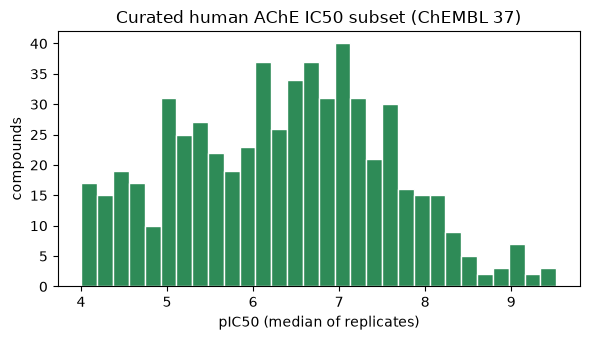

In [12]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(curated["pIC50"], bins=30, color="seagreen", edgecolor="white")
ax.set_xlabel("pIC50 (median of replicates)"); ax.set_ylabel("compounds")
ax.set_title("Curated human AChE IC50 subset (ChEMBL 37)")
plt.tight_layout(); plt.show()

> For a full, reusable pipeline (unit harmonization, PAINS/Brenk alerts, audit reports), see
> [**chem-curate**](https://github.com/hentablihamza/chem-curate). Its steps follow the same logic you just built by hand.

### ✏️ Exercise 1

How many records in the raw table were removed because their relation was not `=`? List the relations that were removed and their counts.

In [13]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
removed = raw[raw["canonical_smiles"].notna() & (raw["standard_relation"] != "=")]
print(len(removed), "records removed")
print(removed["standard_relation"].value_counts(dropna=False))
```

</details>

### ✏️ Exercise 2

Which ChEMBL molecule IDs were merged into a single standardized structure (i.e. one InChIKey with more than one ChEMBL ID)? Show them.

In [14]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
merged = curated[curated["chembl_ids"].str.contains(";")]
print(len(merged), "structures merged from several ChEMBL IDs")
merged[["inchikey", "chembl_ids", "n_measurements", "pIC50"]].head()
```

</details>

### ✏️ Exercise 3

Draw the 4 compounds with the largest disagreement between replicate measurements, with their range as legend.

In [15]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
worst = curated.nlargest(4, "pIC50_range")
Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in worst["smiles"]], molsPerRow=4, subImgSize=(230, 190),
                     legends=[f"n={n}, range={r:.2f}" for n, r in zip(worst.n_measurements, worst.pIC50_range)])
```

</details>

## Key takeaways

- Standardize **before** you deduplicate: salts, charges, and tautomers hide duplicates.
- Filter activity records explicitly and count every step.
- Aggregate replicates (median) and flag compounds whose measurements disagree.

**Next:** [07 · Getting data from ChEMBL](07_chembl_data_access.ipynb).